# PULSE-A Mission Visualization (timestep engine)

Presentation figures from the **new_mission_power_simulation** engine (real STK timing; no fixed 90/55/35 orbit).
Figures are saved to `sim_outputs/figures/`. The old orbit-level / linear BOL→EOL models live in the legacy `mission_power_simulation.py` and are no longer used here.
Minute-level orbit analysis is in `fixviz (2).ipynb`; numbers behind the orbit-requirements slide are in `new_analyze.ipynb` §5.

In [1]:
from __future__ import annotations

import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 0. PATH SETUP
# ==========================================
# Run this notebook from the "PULSE-A Timestep Sim" folder. Data files and
# Basic PB Calculator.py are found automatically in this folder or the parent
# "Orbital Power Budget Sim" folder (including _ORGANIZED/...).
# The engine (new_mission_power_simulation.py) is the importable version of
# new_mission_power_simulation.ipynb - same functions, same equations.
root = Path.cwd()
sys.path.insert(0, str(root))
import new_mission_power_simulation as sim
importlib.reload(sim)          # pick up edits to the engine without restarting

profile_min = sim.find_data_file("PULSEPowerMinE")
profile_max = sim.find_data_file("PULSEPowerMaxE")
power_budget_file = sim.find_power_budget_file()
fig_dir = sim.OUTPUT_DIR / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

print("root               :", root)
print("power-budget model :", power_budget_file)
print("MinE profile       :", profile_min)
print("MaxE profile       :", profile_max)
print("outputs            :", sim.OUTPUT_DIR)


root               : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/PULSE-A Timestep Sim
power-budget model : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/Basic PB Calculator.py
MinE profile       : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/_ORGANIZED/1_IMPORTANT/data/stk_power_v2_download_from_drive/PULSEPowerMinE (1).csv
MaxE profile       : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/_ORGANIZED/1_IMPORTANT/data/stk_power_v2_download_from_drive/PULSEPowerMaxE (1).csv
outputs            : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/PULSE-A Timestep Sim/sim_outputs


In [2]:
# ==========================================
# 1-4. POWER STATES + READ DATA + TIME COLUMNS + GENERATION
# ==========================================
state_powers = sim.get_state_powers(power_budget_file)
print("State powers from Basic PB Calculator (W):")
for name, watts in state_powers.items():
    print(f"  {name:<22} {watts:6.2f}")

data = {
    "PULSEPowerMinE": sim.load_case("PULSEPowerMinE", profile_min, "MinTotalPower"),
    "PULSEPowerMaxE": sim.load_case("PULSEPowerMaxE", profile_max, "MaxTotalPower"),
}
for name, d in data.items():
    sim.add_orbit_clock(d)


State powers from Basic PB Calculator (W):
  No Control               0.54
  Detumble                 5.01
  Sun-Pointing             5.20
  Pointing Away            5.20
  RF Pass                  5.98
  Payload - Calibration   14.59
  Payload - Acquisition   23.55
  Safe Mode                0.64


In [3]:
# Mission / battery assumptions (all from the engine config)
print("Battery capacity     :", sim.BATTERY_CAPACITY_WH, "Wh (flight pack 50.4 Wh run as sensitivity)")
print("Initial / max SoC    :", 100 * sim.INITIAL_SOC_FRACTION, "% /", 100 * sim.MAX_SOC_FRACTION, "%")
print("Thresholds           : 33 % recovery, 20 % warning, 15 % safe mode, 10 % floor")
ops = sim.OpsSchedule()
print("Realistic ops        :", ops)

runs = {}
for case, d in data.items():
    runs[(case, "baseline")] = sim.run_csv_mission_simulation(case, csv_data=d, state_powers=state_powers)
    runs[(case, "realistic ops")] = sim.run_csv_mission_simulation(case, csv_data=d, schedule=ops, state_powers=state_powers)
    runs[(case, "stress")] = sim.run_csv_mission_simulation(case, csv_data=d, schedule=sim.PAYLOAD_EVERY_ORBIT, state_powers=state_powers)
    runs[(case, "9.10 W")] = sim.run_csv_mission_simulation(case, csv_data=d, constant_load_w=9.10, state_powers=state_powers)
summ = {k: sim.summarize_by_orbit(r) for k, r in runs.items()}
for k, r in runs.items():
    m = sim.mission_metrics(r, summ[k])
    print(f"{k[0]:<15} {k[1]:<14} min {m['min_soc_percent']:5.1f} %  final {m['final_soc_percent']:5.1f} %  "
          f"cons {m['mean_cons_wh_orbit']:5.2f} Wh/orbit  gen {m['mean_gen_wh_orbit']:5.2f} Wh/orbit")


Battery capacity     : 40.0 Wh (flight pack 50.4 Wh run as sensitivity)
Initial / max SoC    : 95.0 % / 95.0 %
Thresholds           : 33 % recovery, 20 % warning, 15 % safe mode, 10 % floor
Realistic ops        : OpsSchedule(detumble_hours=6.0, rf_every_n_orbits=3, rf_minutes=10.0, payload_every_n_days=1, payload_minutes=10.0, calib_every_n_days=1, calib_minutes=10.0, use_safe_mode=True, name='realistic ops')


PULSEPowerMinE  baseline       min  87.2 %  final  93.5 %  cons  8.08 Wh/orbit  gen 19.02 Wh/orbit
PULSEPowerMinE  realistic ops  min  78.1 %  final  93.5 %  cons  8.45 Wh/orbit  gen 19.02 Wh/orbit
PULSEPowerMinE  stress         min  78.0 %  final  87.4 %  cons 13.07 Wh/orbit  gen 19.02 Wh/orbit
PULSEPowerMinE  9.10 W         min  81.3 %  final  92.2 %  cons 14.15 Wh/orbit  gen 19.02 Wh/orbit
PULSEPowerMaxE  baseline       min  87.2 %  final  90.2 %  cons  8.08 Wh/orbit  gen 22.22 Wh/orbit
PULSEPowerMaxE  realistic ops  min  78.4 %  final  89.9 %  cons  8.44 Wh/orbit  gen 22.22 Wh/orbit
PULSEPowerMaxE  stress         min  78.2 %  final  81.9 %  cons 13.06 Wh/orbit  gen 22.22 Wh/orbit
PULSEPowerMaxE  9.10 W         min  81.3 %  final  86.7 %  cons 14.14 Wh/orbit  gen 22.22 Wh/orbit


## Figure 1 – Battery SoC over the 2-year mission (realistic operations)

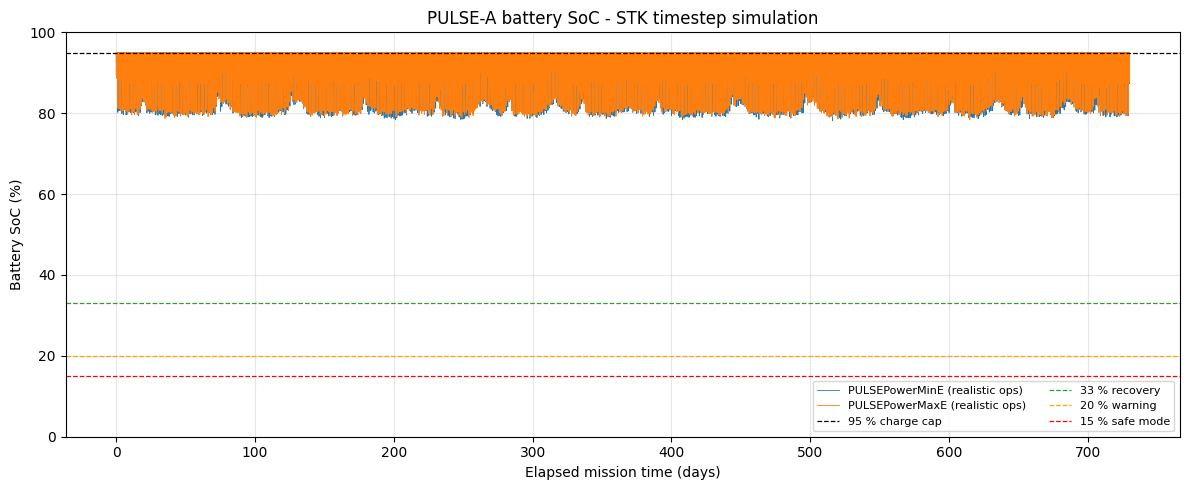

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
for case in data:
    sim.plot_soc(runs[(case, "realistic ops")], ax=ax, label=f"{case} (realistic ops)")
for frac, lab, c in [(0.95, "95 % charge cap", "k"), (0.33, "33 % recovery", "tab:green"),
                     (0.20, "20 % warning", "orange"), (0.15, "15 % safe mode", "red")]:
    ax.axhline(100 * frac, ls="--", lw=0.9, color=c, label=lab)
ax.set_ylim(0, 100); ax.set_title("PULSE-A battery SoC - STK timestep simulation")
ax.legend(loc="lower right", ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig(fig_dir / "fig1_soc_mission.png", dpi=200); plt.show()


## Figure 2 – Real orbit timing (replaces the 90 / 55 / 35-min assumption)

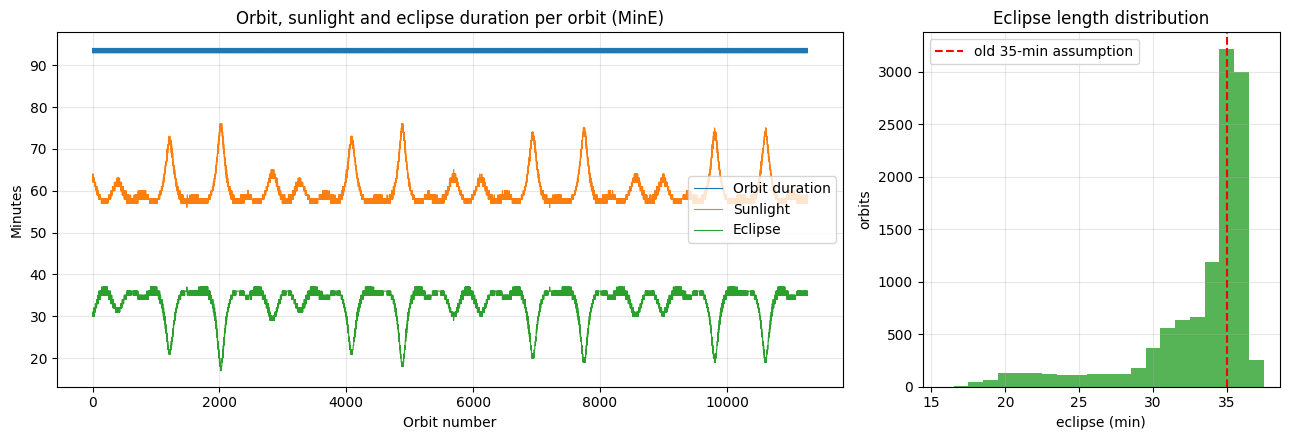

full orbits: 11268, duration 93.29 min (range 93-94), eclipse 17-37 min, sunlight 56-76 min


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
s = summ[("PULSEPowerMinE", "baseline")]; full = sim.orbit_flags(s)["full"]
sim.plot_orbit_timing("PULSEPowerMinE", s[full], ax=axes[0])
axes[0].set_title("Orbit, sunlight and eclipse duration per orbit (MinE)")
axes[1].hist(s[full, sim.COL["eclipse_min"]], bins=np.arange(15.5, 38.5, 1), color="tab:green", alpha=0.8)
axes[1].axvline(35, color="r", ls="--", label="old 35-min assumption")
axes[1].set_xlabel("eclipse (min)"); axes[1].set_ylabel("orbits"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title("Eclipse length distribution")
plt.tight_layout(); plt.savefig(fig_dir / "fig2_orbit_timing.png", dpi=200); plt.show()
print(f"full orbits: {full.sum()}, duration {s[full,1].mean():.2f} min (range {s[full,1].min():.0f}-{s[full,1].max():.0f}), "
      f"eclipse {s[full,2].min():.0f}-{s[full,2].max():.0f} min, sunlight {s[full,3].min():.0f}-{s[full,3].max():.0f} min")


## Figure 3 – Per-orbit generation vs consumption

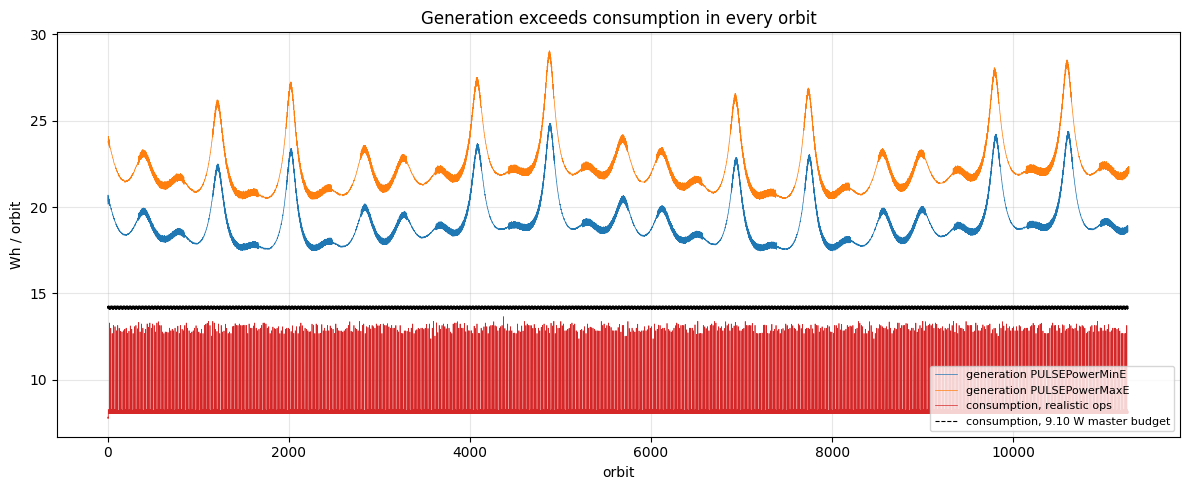

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
for case in data:
    s = summ[(case, "realistic ops")]; full = sim.orbit_flags(s)["full"]
    ax.plot(s[full, 0], s[full, sim.COL["generation_wh"]], lw=0.5, label=f"generation {case}")
s = summ[("PULSEPowerMinE", "realistic ops")]; full = sim.orbit_flags(s)["full"]
ax.plot(s[full, 0], s[full, sim.COL["consumption_wh"]], lw=0.5, color="tab:red", label="consumption, realistic ops")
s9 = summ[("PULSEPowerMinE", "9.10 W")]; f9 = sim.orbit_flags(s9)["full"]
ax.plot(s9[f9, 0], s9[f9, sim.COL["consumption_wh"]], lw=0.8, color="k", ls="--", label="consumption, 9.10 W master budget")
ax.set_xlabel("orbit"); ax.set_ylabel("Wh / orbit"); ax.grid(alpha=0.3); ax.legend(loc="lower right", fontsize=8)
ax.set_title("Generation exceeds consumption in every orbit")
plt.tight_layout(); plt.savefig(fig_dir / "fig3_generation_vs_consumption.png", dpi=200); plt.show()


## Figure 4 – First 10 orbits: SoC and spacecraft state (detumble → nominal)

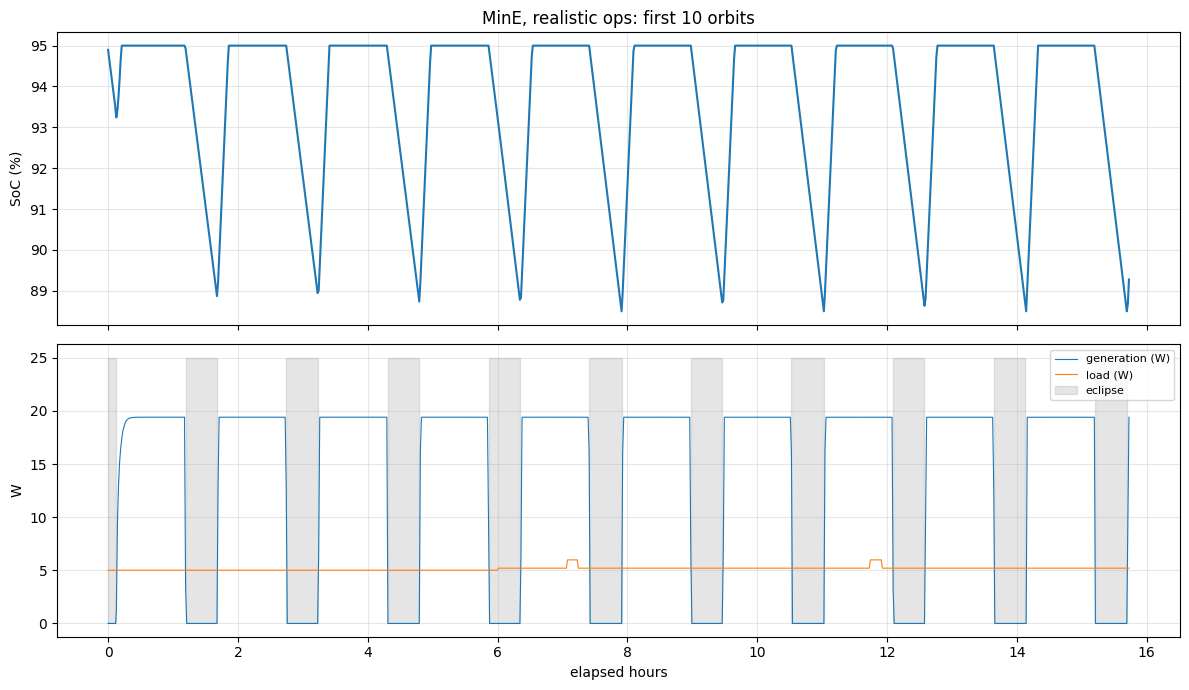

In [7]:
r = runs[("PULSEPowerMinE", "realistic ops")]
mask = r["orbit_number"] <= 11
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(r["elapsed_hours"][mask], r["soc_percent"][mask], color="tab:blue")
axes[0].set_ylabel("SoC (%)"); axes[0].grid(alpha=0.3); axes[0].set_title("MinE, realistic ops: first 10 orbits")
axes[1].plot(r["elapsed_hours"][mask], r["generation_wh"][mask] / r["dt_hours"][mask], lw=0.8, label="generation (W)")
axes[1].plot(r["elapsed_hours"][mask], r["power_draw_w"][mask], lw=0.8, label="load (W)")
axes[1].fill_between(r["elapsed_hours"][mask], 0, 25, where=r["in_shadow"][mask] == 1, color="gray", alpha=0.2, label="eclipse")
axes[1].set_xlabel("elapsed hours"); axes[1].set_ylabel("W"); axes[1].grid(alpha=0.3); axes[1].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(fig_dir / "fig4_first_orbits.png", dpi=200); plt.show()


## Figure 5 – Scenario comparison (minimum SoC)

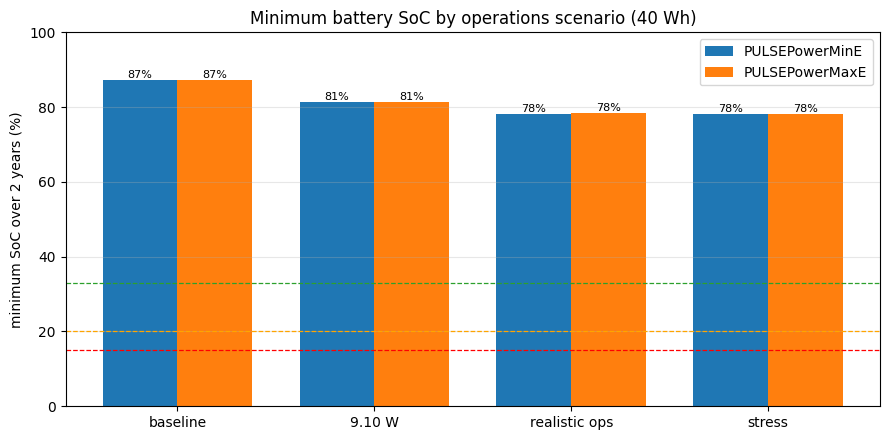

In [8]:
labels = ["baseline", "9.10 W", "realistic ops", "stress"]
x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
for j, case in enumerate(data):
    vals = [runs[(case, l)]["soc_percent"].min() for l in labels]
    bars = ax.bar(x + (j - 0.5) * w, vals, w, label=case)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8)
for frac, c in [(0.33, "tab:green"), (0.20, "orange"), (0.15, "red")]:
    ax.axhline(100 * frac, ls="--", color=c, lw=0.9)
ax.set_xticks(x, labels); ax.set_ylabel("minimum SoC over 2 years (%)"); ax.set_ylim(0, 100); ax.legend(); ax.grid(axis="y", alpha=0.3)
ax.set_title("Minimum battery SoC by operations scenario (40 Wh)")
plt.tight_layout(); plt.savefig(fig_dir / "fig5_scenarios.png", dpi=200); plt.show()


## Figure 6 – Orbit envelope for the requirements slide

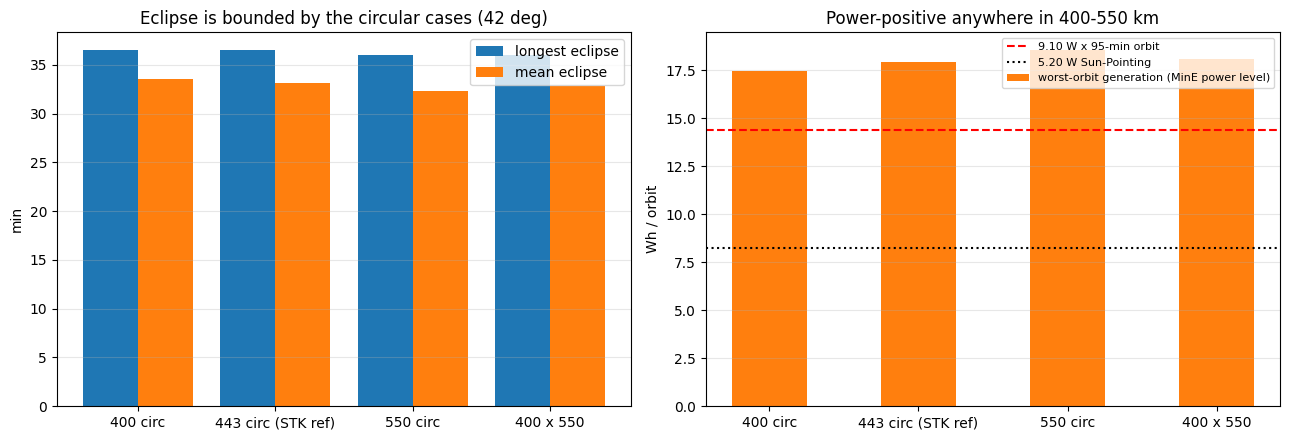

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cases = [("400 circ", 400, 400), ("443 circ (STK ref)", 443, 443), ("550 circ", 550, 550), ("400 x 550", 400, 550)]
p_sun = float(np.nanmean(data["PULSEPowerMinE"]["generation_w"][data["PULSEPowerMinE"]["in_shadow"] == 0]))
emax, emean, gmin = [], [], []
for _, hp, ha in cases:
    pr = sim.propagate_eclipse_profile(hp, ha, 42.0, days=365, dt_min=0.5)
    emax.append(pr["eclipse_min"].max()); emean.append(pr["eclipse_min"].mean()); gmin.append((p_sun * pr["sunlight_min"] / 60).min())
x = np.arange(len(cases))
axes[0].bar(x - 0.2, emax, 0.4, label="longest eclipse"); axes[0].bar(x + 0.2, emean, 0.4, label="mean eclipse")
axes[0].set_xticks(x, [c[0] for c in cases]); axes[0].set_ylabel("min"); axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)
axes[0].set_title("Eclipse is bounded by the circular cases (42 deg)")
axes[1].bar(x, gmin, 0.5, color="tab:orange", label="worst-orbit generation (MinE power level)")
axes[1].axhline(9.10 * 95 / 60, color="r", ls="--", label="9.10 W x 95-min orbit")
axes[1].axhline(5.20 * 95 / 60, color="k", ls=":", label="5.20 W Sun-Pointing")
axes[1].set_xticks(x, [c[0] for c in cases]); axes[1].set_ylabel("Wh / orbit"); axes[1].legend(fontsize=8); axes[1].grid(axis="y", alpha=0.3)
axes[1].set_title("Power-positive anywhere in 400-550 km")
plt.tight_layout(); plt.savefig(fig_dir / "fig6_orbit_envelope.png", dpi=200); plt.show()
